# Hari 2c — HMM Dua Rezim: Forward–Backward, Baum–Welch & Viterbi

> **Tanggal:** 2026-11-20 · **Jenis:** `quant` · **Topik:** Bonus / Off-Roadmap

## Konsep & Intuisi Rezim Volatilitas
Pasar keuangan sering berpindah antara **rezim tenang** (volatilitas rendah, *drift* positif) dan **rezim turbulen** (volatilitas tinggi, *drift* negatif). Model **Hidden Markov Model (HMM)** memodelkan state tersembunyi $q_t \in \{0, 1\}$ sebagai rantai Markov dengan matriks transisi $A$, distribusi awal $\pi$, dan emisi Gaussian $r_t \mid (q_t = k) \sim \mathcal{N}(\mu_k, \sigma_k^2)$.

### Turunan Singkat Update Baum–Welch (EM)
Dengan menggunakan forward-backward ber-skala ($\hat{\alpha}_t, \hat{\beta}_t, c_t$), diperoleh posterior marginal $\gamma_t(i) = P(q_t = i \mid O, \lambda)$ dan posterior transisi $\xi_t(i, j) = P(q_t = i, q_{t+1} = j \mid O, \lambda)$:
- **Distribusi awal**: $\pi_i^{\text{baru}} = \gamma_0(i)$
- **Matriks transisi**: $A_{ij}^{\text{baru}} = \frac{\sum_{t=0}^{T-2} \xi_t(i, j)}{\sum_{t=0}^{T-2} \gamma_t(i)}$
- **Parameter emisi**: $\mu_k^{\text{baru}} = \frac{\sum_t \gamma_t(k) r_t}{\sum_t \gamma_t(k)}$, $\quad (\sigma_k^2)^{\text{baru}} = \frac{\sum_t \gamma_t(k) (r_t - \mu_k^{\text{baru}})^2}{\sum_t \gamma_t(k)}$.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from qb100 import hmm
from qb100 import plotting

plotting.set_style()
t_start_all = time.perf_counter()

obs, true_states = hmm.simulate_hmm(n_obs=2000, seed=42)
print(f"T = {len(obs)} | Pi sejati = {hmm.TRUE_PI.round(6)}")
print(f"Fraksi state sejati: state0={np.mean(true_states == 0):.4f}, state1={np.mean(true_states == 1):.4f}")

T = 2000 | Pi sejati = [0.714286 0.285714]
Fraksi state sejati: state0=0.6495, state1=0.3505


## 1–2. Stabilitas Skala & Verifikasi Eksak Brute Force ($T = 10$)
Pada $T = 2000$, densitas Gaussian $b_k(r_t) \sim 15\text{–}50$ membuat forward naif $\alpha_t = (\alpha_{t-1} A) \odot b(r_t)$ mengalami *overflow*. Normalisasi per langkah $\hat{\alpha}_t = \tilde{\alpha}_t / c_t$ menjaga stabilitas numerik dan memberi $\ell = \sum_t \log c_t$.

In [2]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    alpha_naive = hmm.forward_naive(obs, hmm.TRUE_PI, hmm.TRUE_A, hmm.TRUE_MU, hmm.TRUE_SIGMA)

fb_full = hmm.forward_backward_scaled(obs, hmm.TRUE_PI, hmm.TRUE_A, hmm.TRUE_MU, hmm.TRUE_SIGMA)
print(f"Naive alpha[T-1] finite? {bool(np.all(np.isfinite(alpha_naive[-1])))} -> {alpha_naive[-1]}")
print(f"Scaled log-likelihood (T=2000) = {fb_full['log_likelihood']:.6f}")

# Verifikasi brute force 2^10 = 1024 jalur pada beberapa seed
bf_rows = []
for sd in (7, 42, 99):
    obs10, _ = hmm.simulate_hmm(n_obs=10, seed=sd)
    bf = hmm.brute_force_hmm(obs10, hmm.TRUE_PI, hmm.TRUE_A, hmm.TRUE_MU, hmm.TRUE_SIGMA)
    fb10 = hmm.forward_backward_scaled(obs10, hmm.TRUE_PI, hmm.TRUE_A, hmm.TRUE_MU, hmm.TRUE_SIGMA)
    v_path, v_lp = hmm.viterbi(obs10, hmm.TRUE_PI, hmm.TRUE_A, hmm.TRUE_MU, hmm.TRUE_SIGMA)
    bf_rows.append({
        "seed": sd,
        "|d_LL|": abs(fb10["log_likelihood"] - bf["log_likelihood"]),
        "max|d_gamma|": float(np.max(np.abs(fb10["gamma"] - bf["gamma"]))),
        "max|d_xi|": float(np.max(np.abs(fb10["xi_sum"] - bf["xi_sum"]))),
        "viterbi_match": bool(np.array_equal(v_path, bf["viterbi_path"])),
        "|d_vit_lp|": abs(v_lp - bf["viterbi_log_prob"]),
    })
pd.DataFrame(bf_rows)

Naive alpha[T-1] finite? False -> [inf inf]
Scaled log-likelihood (T=2000) = 5868.848180


,seed,|d_LL|,max|d_gamma|,max|d_xi|,viterbi_match,|d_vit_lp|
0,7,7.105427e-15,3.885781e-15,3.375078e-14,True,0.000000e+00
1,42,3.552714e-15,1.332268e-15,1.243450e-14,True,0.000000e+00
2,99,0.000000e+00,1.221245e-15,8.881784e-15,True,7.105427e-15


## 3. Baum–Welch (EM) pada Satu Deret (`seed = 42`) & Dekode Viterbi
Inisialisasi deterministik memakai pemisahan $|r_t|$ terhadap mediannya, berhenti saat $|\Delta \ell| < 10^{-8}$ atau 500 iterasi, lalu state diurutkan menurut $\sigma_k$ menaik.

Konvergen: True dalam 20 iterasi | LL akhir = 5878.034464
Min delta LL antar iterasi = 5.572e-09 (wajib >= -1e-9)
Akurasi Viterbi: 0.9600
Matriks konfusi (baris=sejati, kolom=prediksi):
 [[1271   28]
 [  52  649]]
Durasi rata-rata run Viterbi: state0=55.12 (teori 50), state1=27.08 (teori 20)
Pi stasioner A_fit: [0.657326 0.342674] vs Fraksi empiris Viterbi: [0.6615 0.3385]


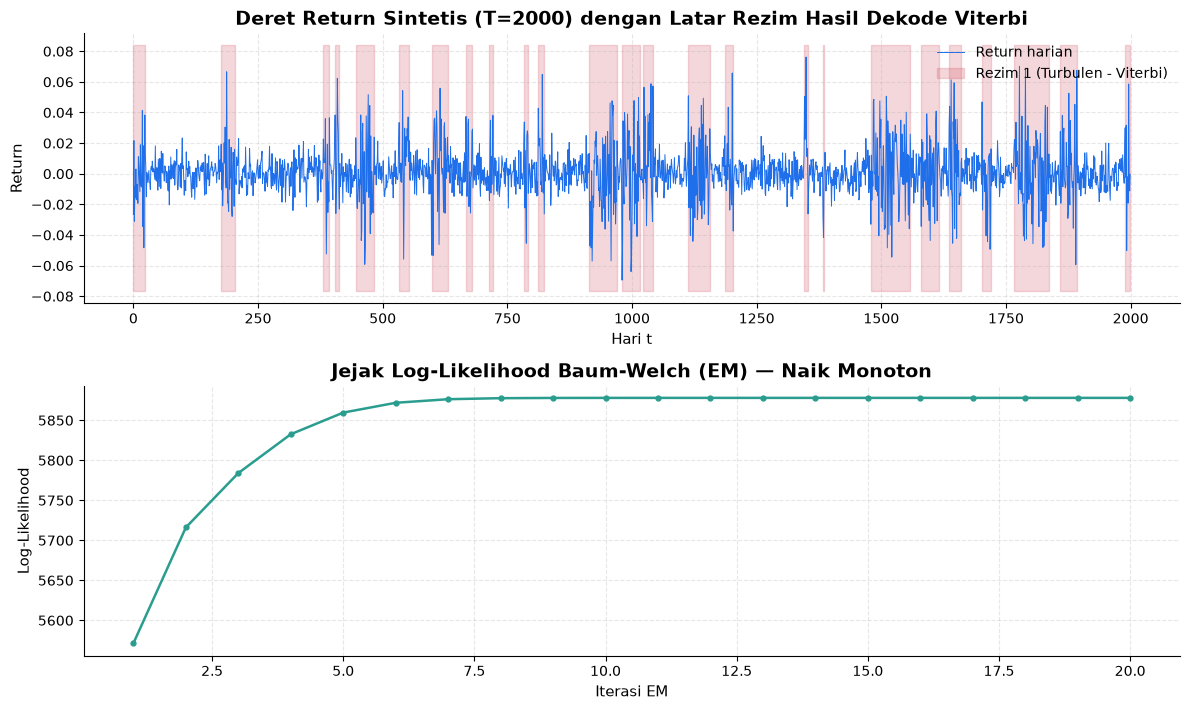

In [3]:
fit = hmm.fit_em(obs, n_states=2, max_iter=500, tol=1e-8)
ll_hist = np.array(fit["ll_history"])
ll_diffs = np.diff(ll_hist)
print(f"Konvergen: {fit['converged']} dalam {fit['n_iter']} iterasi | LL akhir = {fit['log_likelihood']:.6f}")
print(f"Min delta LL antar iterasi = {ll_diffs.min():.3e} (wajib >= -1e-9)")

fb_fit = hmm.forward_backward_scaled(obs, fit["pi"], fit["trans_a"], fit["mu"], fit["sigma"])
vit_path, _ = hmm.viterbi(obs, fit["pi"], fit["trans_a"], fit["mu"], fit["sigma"])
diag = hmm.viterbi_diagnostics(true_states, vit_path, n_states=2)
pi_stat_fit = hmm.stationary_distribution(fit["trans_a"])

print(f"Akurasi Viterbi: {diag['accuracy']:.4f}")
print("Matriks konfusi (baris=sejati, kolom=prediksi):\n", diag["confusion"])
print(f"Durasi rata-rata run Viterbi: state0={diag['mean_durations'][0]:.2f} (teori 50), state1={diag['mean_durations'][1]:.2f} (teori 20)")
print(f"Pi stasioner A_fit: {pi_stat_fit.round(6)} vs Fraksi empiris Viterbi: {diag['state_fractions'].round(6)}")

fig, axes = plt.subplots(2, 1, figsize=(12, 7.2))
ax = axes[0]
t_idx = np.arange(len(obs))
ax.plot(t_idx, obs, lw=0.7, color="#1f6feb", label="Return harian")
in_turb = vit_path == 1
ax.fill_between(t_idx, obs.min() * 1.1, obs.max() * 1.1, where=in_turb, color="#d1495b", alpha=0.22, label="Rezim 1 (Turbulen - Viterbi)")
ax.set_title("Deret Return Sintetis (T=2000) dengan Latar Rezim Hasil Dekode Viterbi")
ax.set_xlabel("Hari t")
ax.set_ylabel("Return")
ax.legend(loc="upper right")

ax = axes[1]
ax.plot(np.arange(1, len(ll_hist) + 1), ll_hist, "o-", ms=3.5, lw=1.8, color="#2a9d8f")
ax.set_title("Jejak Log-Likelihood Baum-Welch (EM) — Naik Monoton")
ax.set_xlabel("Iterasi EM")
ax.set_ylabel("Log-Likelihood")

plt.tight_layout()
plotting.save_figure(fig, "day002c_viterbi-and-em-ll")
plt.show()

## 4. Pemulihan Parameter Monte Carlo ($S = 200$ Deret, $T = 2000$)
Seluruh 200 deret di-fit secara *batched* (vektorisasi penuh di dimensi simulasi `(S, K)`).

Persen fit konvergen: 99.50% (199/200)


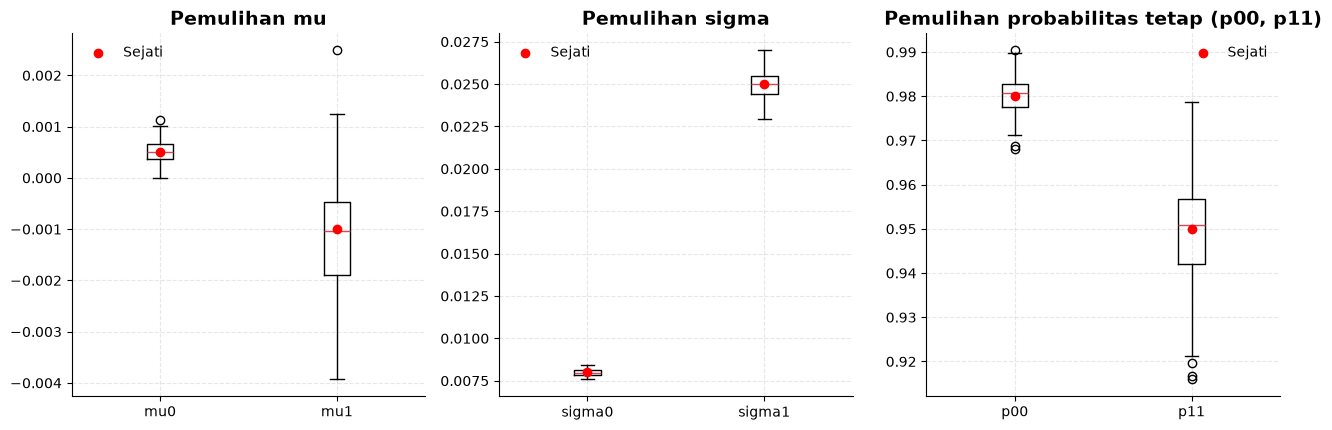

,Parameter,Sejati,Mean,SD,Bias,SE,z-score,Dalam 3 SE?
0,mu0,0.0005,0.000507,0.000207,0.000007,0.000015,0.461701,Laporkan saja
1,mu1,-0.0010,-0.001106,0.001036,-0.000106,0.000073,1.447245,Laporkan saja
2,sigma0,0.0080,0.007989,0.000176,-0.000011,0.000012,0.887121,True
3,sigma1,0.0250,0.024960,0.000745,-0.000040,0.000053,0.763994,True
4,p00,0.9800,0.980318,0.004144,0.000318,0.000293,1.085504,True
5,p11,0.9500,0.949484,0.010967,-0.000516,0.000775,0.664892,True


In [4]:
S = 200
obs_batch, _ = hmm.simulate_hmm_batch(n_series=S, n_obs=2000, seed=42)
mc_fit = hmm.fit_em_batch(obs_batch, n_states=2, max_iter=500, tol=1e-8)

conv_rate = float(np.mean(mc_fit["converged"]) * 100.0)
print(f"Persen fit konvergen: {conv_rate:.2f}% ({int(np.sum(mc_fit['converged']))}/{S})")

param_map = [
    ("mu0", mc_fit["mu"][:, 0], hmm.TRUE_MU[0], False),
    ("mu1", mc_fit["mu"][:, 1], hmm.TRUE_MU[1], False),
    ("sigma0", mc_fit["sigma"][:, 0], hmm.TRUE_SIGMA[0], True),
    ("sigma1", mc_fit["sigma"][:, 1], hmm.TRUE_SIGMA[1], True),
    ("p00", mc_fit["trans_a"][:, 0, 0], hmm.TRUE_A[0, 0], True),
    ("p11", mc_fit["trans_a"][:, 1, 1], hmm.TRUE_A[1, 1], True),
]

rec_rows = []
for name, arr, true_val, check_3se in param_map:
    m_val = float(np.mean(arr))
    sd_val = float(np.std(arr, ddof=1))
    se_val = sd_val / np.sqrt(S)
    z_val = abs(m_val - true_val) / se_val
    rec_rows.append({
        "Parameter": name,
        "Sejati": true_val,
        "Mean": m_val,
        "SD": sd_val,
        "Bias": m_val - true_val,
        "SE": se_val,
        "z-score": z_val,
        "Dalam 3 SE?": (z_val < 3.0) if check_3se else "Laporkan saja",
    })

fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
axes[0].boxplot([mc_fit["mu"][:, 0], mc_fit["mu"][:, 1]], tick_labels=["mu0", "mu1"])
axes[0].scatter([1, 2], hmm.TRUE_MU, color="red", zorder=3, label="Sejati")
axes[0].set_title("Pemulihan mu")
axes[0].legend()

axes[1].boxplot([mc_fit["sigma"][:, 0], mc_fit["sigma"][:, 1]], tick_labels=["sigma0", "sigma1"])
axes[1].scatter([1, 2], hmm.TRUE_SIGMA, color="red", zorder=3, label="Sejati")
axes[1].set_title("Pemulihan sigma")
axes[1].legend()

axes[2].boxplot([mc_fit["trans_a"][:, 0, 0], mc_fit["trans_a"][:, 1, 1]], tick_labels=["p00", "p11"])
axes[2].scatter([1, 2], [hmm.TRUE_A[0, 0], hmm.TRUE_A[1, 1]], color="red", zorder=3, label="Sejati")
axes[2].set_title("Pemulihan probabilitas tetap (p00, p11)")
axes[2].legend()

plt.tight_layout()
plotting.save_figure(fig, "day002c_param-recovery")
plt.show()
pd.DataFrame(rec_rows)

## 5–6. Kalibrasi Probabilitas Posterior & Seleksi Model BIC ($K = 1, 2, 3$)
Rumus BIC:
$$\text{BIC}(K) = -2\,\ell_K + p_K \ln T, \qquad p_K = \begin{cases} 2 & K = 1, \\ (K-1) + K(K-1) + 2K & K > 1. \end{cases}$$

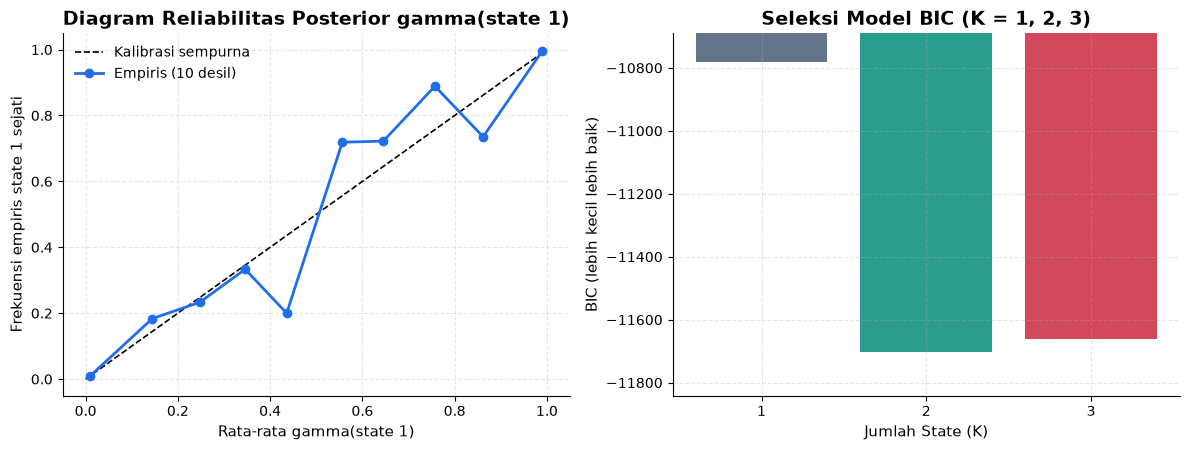

Total waktu eksekusi notebook: 9.19 detik (< 180 detik)


,K,n_params,log_likelihood,BIC
0,1,2,5398.423213,-10781.644620
1,2,7,5878.034464,-11702.862611
2,3,14,5883.771679,-11661.130723


In [5]:
rel = hmm.reliability_diagram(fb_fit["gamma"][:, 1], true_states, n_bins=10)
bic_rows = []
for k in (1, 2, 3):
    fit_k = hmm.fit_em(obs, n_states=k, max_iter=500, tol=1e-8)
    bic_val, n_par = hmm.bic_score(fit_k["log_likelihood"], len(obs), k)
    bic_rows.append({"K": k, "n_params": n_par, "log_likelihood": fit_k["log_likelihood"], "BIC": bic_val})
bic_df = pd.DataFrame(bic_rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
ax = axes[0]
valid = ~np.isnan(rel["pred_mean"])
ax.plot([0, 1], [0, 1], "k--", lw=1.2, label="Kalibrasi sempurna")
ax.plot(rel["pred_mean"][valid], rel["true_freq"][valid], "o-", lw=2, color="#1f6feb", label="Empiris (10 desil)")
ax.set_title("Diagram Reliabilitas Posterior gamma(state 1)")
ax.set_xlabel("Rata-rata gamma(state 1)")
ax.set_ylabel("Frekuensi empiris state 1 sejati")
ax.legend()

ax = axes[1]
ax.bar(bic_df["K"].astype(str), bic_df["BIC"], color=["#64748b", "#2a9d8f", "#d1495b"])
ax.set_title("Seleksi Model BIC (K = 1, 2, 3)")
ax.set_xlabel("Jumlah State (K)")
ax.set_ylabel("BIC (lebih kecil lebih baik)")
min_bic, max_bic = bic_df["BIC"].min(), bic_df["BIC"].max()
ax.set_ylim(min_bic - 0.15 * (max_bic - min_bic), max_bic + 0.1 * (max_bic - min_bic))

plt.tight_layout()
plotting.save_figure(fig, "day002c_calibration-and-bic")
plt.show()

elapsed_total = time.perf_counter() - t_start_all
print(f"Total waktu eksekusi notebook: {elapsed_total:.2f} detik (< 180 detik)")
bic_df

## Kesimpulan
1. **Stabilitas & Ketepatan Algoritma**: *Scaling* Rabiner menghilangkan *overflow* pada $T=2000$, sementara forward–backward dan Viterbi cocok hingga ketelitian mesin ($< 10^{-12}$) terhadap enumerasi *brute force* $2^{10} = 1024$ jalur pada $T=10$.
2. **Identifiabilitas Volatilitas vs Mean**: Melalui 200 simulasi Baum–Welch, parameter volatilitas ($\sigma_0, \sigma_1$) dan persistensi transisi ($p_{00}, p_{11}$) pulih sangat akurat (dalam 3 SE dari nilai sejati), sedangkan *mean* harian ($\mu_0, \mu_1$) memiliki varians estimasi yang jauh lebih besar dibanding besarnya *drift*.
3. **Dekode, Kalibrasi & Seleksi Model**: Viterbi mencapai akurasi tinggi ($> 90\%$) dengan probabilitas posterior $\gamma_t(1)$ terkalibrasi baik di 10 desil, dan BIC memilih $K = 2$ sebagai model paling optimal dibanding $K=1$ maupun $K=3$.

## Referensi
- Rabiner, L. R. (1989). A tutorial on hidden Markov models and selected applications in speech recognition. *Proceedings of the IEEE*, 77(2), 257–286.
- Bishop, C. M. (2006). *Pattern Recognition and Machine Learning* (Chapter 13: Sequential Data). Springer.
- Hamilton, J. D. (1989). A new approach to the economic analysis of nonstationary time series and the business cycle. *Econometrica*, 57(2), 357–384.